# Part 2: PAC-Bayesian Bounds

## 1. Compute the bounds

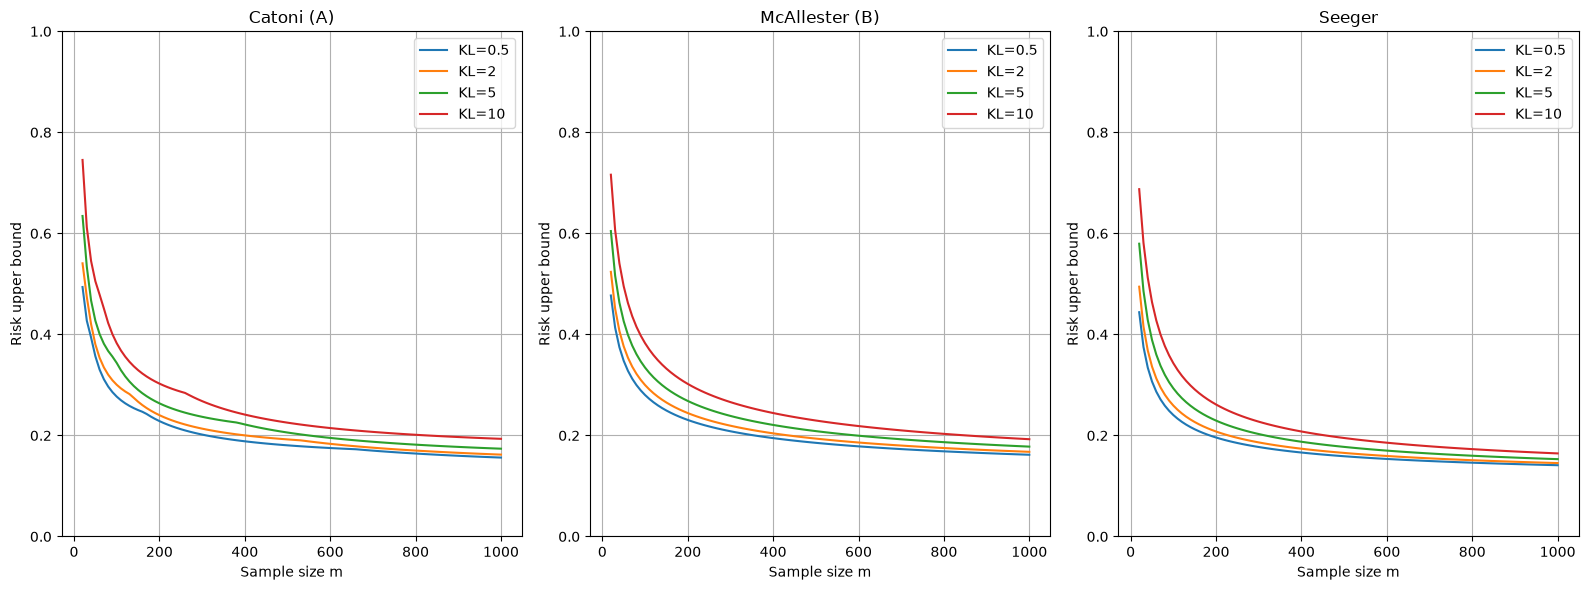

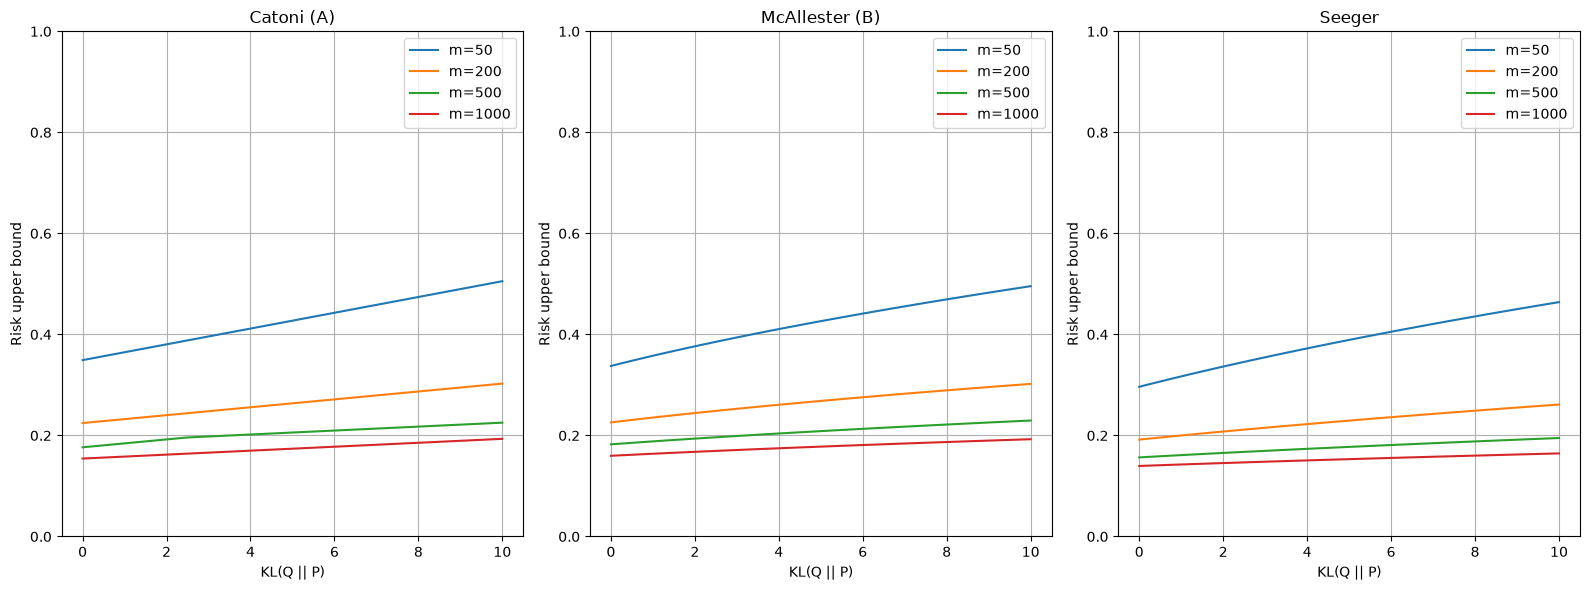

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent   # notebook is run from code/
sys.path[:0] = [str(ROOT), str(ROOT / "code")]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pacbayes_tools import *
from benchkit import *
from scipy.spatial.distance import jensenshannon


EMP = 0.1
KL_VALUES = [0.5, 2, 5, 10]
M_RANGE = np.arange(20, 1001, 10)
M_VALUES = [50, 200, 500, 1000]
KL_RANGE = np.linspace(0, 10, 100)


def compute_bounds(m, kl, emp=EMP):
    # Choose the best lambda from the predefined grid
    A = min(
        bound_linear(emp, kl, m, lam, DELTA, len(GRID))
        for lam in GRID
    )

    B = bound_mcallester(emp, kl, m, DELTA)
    S = bound_seeger(emp, kl, m, DELTA)

    return A, B, S


fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for kl in KL_VALUES:
    values = np.array([compute_bounds(m, kl) for m in M_RANGE])

    axes[0].plot(M_RANGE, values[:, 0], label=f"KL={kl}")
    axes[1].plot(M_RANGE, values[:, 1], label=f"KL={kl}")
    axes[2].plot(M_RANGE, values[:, 2], label=f"KL={kl}")

for ax, title in zip(axes, ["Catoni (A)", "McAllester (B)", "Seeger"]):
    ax.set_title(title)
    ax.set_xlabel("Sample size m")
    ax.set_ylabel("Risk upper bound")
    ax.set_ylim(0, 1)
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(16, 6))

for m in M_VALUES:
    values = np.array([compute_bounds(m, kl) for kl in KL_RANGE])

    axes[0].plot(KL_RANGE, values[:, 0], label=f"m={m}")
    axes[1].plot(KL_RANGE, values[:, 1], label=f"m={m}")
    axes[2].plot(KL_RANGE, values[:, 2], label=f"m={m}")

for ax, title in zip(axes, ["Catoni (A)", "McAllester (B)", "Seeger"]):
    ax.set_title(title)
    ax.set_xlabel("KL(Q || P)")
    ax.set_ylabel("Risk upper bound")
    ax.set_ylim(0, 1)
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

As expected, bounds get tighter as it diverges less from the prior and gets more data. The Seeger bound is tightest.

How does bound A depend on $\lambda$?

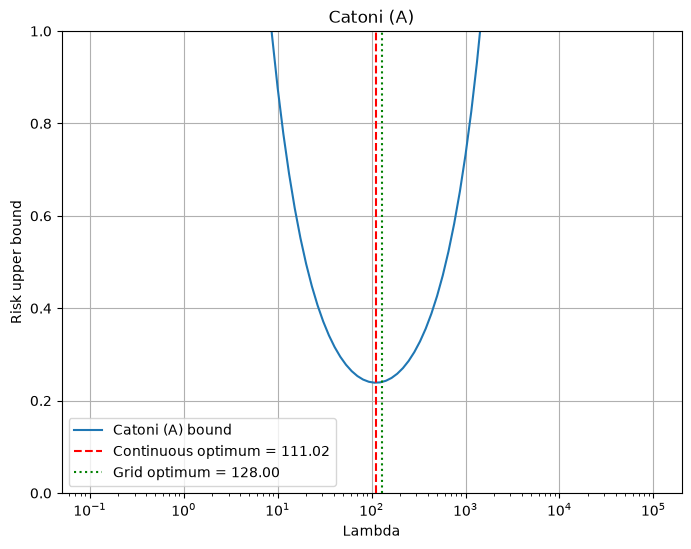

In [2]:
m = 200
kl = 2
lambdas = np.logspace(-1, 5, 100)

bounds = [
    bound_linear(EMP, kl, m, lam, DELTA, len(GRID))
    for lam in lambdas
]

C = kl + np.log(len(GRID) / DELTA)
lambda_star = np.sqrt(8 * m * C)

plt.figure(figsize=(8, 6))
plt.plot(lambdas, bounds, label="Catoni (A) bound")
plt.axvline(lambda_star, linestyle="--", color="red", label=f"Continuous optimum = {lambda_star:.2f}")

# Mark the best lambda actually available in the grid
best_lambda = min(
    GRID,
    key=lambda lam: bound_linear(EMP, kl, m, lam, DELTA, len(GRID))
)

plt.axvline(best_lambda, linestyle=":", color="green", label=f"Grid optimum = {best_lambda:.2f}")

plt.xscale("log")
plt.xlabel("Lambda")
plt.ylabel("Risk upper bound")
plt.ylim(0, 1)
plt.title("Catoni (A)")
plt.grid()
plt.legend()
plt.show()

It's a convex relation as $\lambda$ is a balance between minimizing risk and complexity. The price of the grid is a looser bound.

## 2. Compare the two bounds
Datasets:
- wdbc.
- sonar: high-dimensional measurements with a small sample size; potentially difficult to generalize, thus we can observe how KL penalities differ.
- ioni: similarly small dataset.
- german: noisy problem.
- spambase: larger dataset, useful for checking whether results change with sample size.
- satimage: similarly large dataset.
- additive: ideal for decision stumps, thus KL penalties can be compared with sonar.
- checkerboard: stumps struggle with feature interactions.

Each dataset is run with a few different seeds to reduce uncertainty.

`pacbayes_tools.py` was modified to get the second output of `learn_linear_categorical`.

We also use jenshenshannon to mesure similarity between posteriors which is based on KL.

In [3]:
REAL_DATASETS = ["wdbc", "sonar", "german", "spambase", "satimage", "iono"]
SYNTHETIC_DATASETS = ["additive", "checkerboard"]
DATASETS = REAL_DATASETS + SYNTHETIC_DATASETS
SEEDS = [0, 1, 2, 3, 4, 5, 6]
SYNTHETIC_M = 1000


def get_dataset(name, seed):
    if name == "additive":
        return additive(SYNTHETIC_M, seed=seed)
    elif name == "checkerboard":
        return checkerboard(SYNTHETIC_M, seed=seed)
    return real_dataset(name)


rows = []
similarity_rows = []
wdbc_lambda_rows = []

for name in DATASETS:
    for seed in SEEDS:
        X, y = get_dataset(name, seed)

        out = run_categorical(X, y, seed)

        QA = out["A (linear)"]["Q"]
        QB = out["B (McAllester)"]["Q"]

        # Posterior similarity metrics
        jensenshannon_dist = float(jensenshannon(QA, QB))
        total_variation_dist = float(0.5 * np.sum(np.abs(QA - QB)))
        cos_sim = float(QA @ QB / (np.linalg.norm(QA) * np.linalg.norm(QB)))
        top_match = bool(np.argmax(QA) == np.argmax(QB))

        similarity_rows.append({
            "dataset": name,
            "seed": seed,
            "cos_sim": cos_sim,
            "jensenshannon_dist": jensenshannon_dist,
            "total_variation_dist": total_variation_dist,
            "top_match": top_match,
        })

        for algo_name in ["A (linear)", "B (McAllester)"]:
            r = out[algo_name]
            rows.append({
                "dataset": name,
                "seed": seed,
                "algorithm": algo_name,
                **r
            })

        if name == "wdbc":
            As = out["A (linear)"]["As"]
            for A in As:
                wdbc_lambda_rows.append({
                    "seed": seed,
                    **A
                })

df_results = pd.DataFrame(rows)
df_sim = pd.DataFrame(similarity_rows)
df_wdbc_lambda = pd.DataFrame(wdbc_lambda_rows)

summary_table = (
    df_results.drop(["Q", "As", "seed"], axis=1).groupby(["dataset", "algorithm"]).agg(["mean", "std"]).round(4)
)
print("Bounds and test risks (Mean ± Std over some seeds)")
display(summary_table)

sim_table = (
    df_sim.drop(["seed"], axis=1).groupby("dataset").agg(["mean", "std"]).round(4)
)

print("Posterior Similarity between Q_A (Linear) and Q_B (McAllester) (Mean ± Std over some seeds)")
display(sim_table)

Bounds and test risks (Mean ± Std over some seeds)


bound          seeger              KL          \
                               mean     std    mean     std    mean     std   
dataset      algorithm                                                        
additive     A (linear)      0.3243  0.0199  0.3181  0.0219  5.1903  0.2501   
             B (McAllester)  0.3283  0.0198  0.3181  0.0219  5.2010  0.2574   
checkerboard A (linear)      0.5542  0.0066  0.5566  0.0062  2.1268  1.1270   
             B (McAllester)  0.5565  0.0060  0.5563  0.0060  2.2268  0.9306   
german       A (linear)      0.3782  0.0059  0.3764  0.0060  3.7374  0.8956   
             B (McAllester)  0.3812  0.0052  0.3764  0.0059  3.4839  1.1488   
iono         A (linear)      0.3326  0.0130  0.3146  0.0163  5.8096  0.3017   
             B (McAllester)  0.3369  0.0130  0.3145  0.0163  5.8542  0.3047   
satimage     A (linear)      0.1663  0.0023  0.1577  0.0027  4.7279  0.5128   
             B (McAllester)  0.1698  0.0024  0.1575  0.0028  5.0142  0.5490   
sonar        A (linear)      0.4644  0.0223  0.4544  0.0249  5.9841  0.7167   
             B (McAllester)  0.4643  0.0229  0.4556  0.0261  6.2717  0.9908   
spambase     A (linear)      0.2565  0.0032  0.2527  0.0035  5.4279  0.3644   
             B (McAllester)  0.2603  0.0032  0.2527  0.0035  5.6047  0.4009   
wdbc         A (linear)      0.2097  0.0088  0.1697  0.0115  4.5931  0.1572   
             B (McAllester)  0.2120  0.0092  0.1681  0.0117  5.3369  0.7262   

                                emp            neff         test_gibbs  \
                               mean     std    mean     std       mean   
dataset      algorithm                                                   
additive     A (linear)      0.2246  0.0206  1.1341  0.3404     0.2223   
             B (McAllester)  0.2246  0.0207  1.1325  0.3506     0.2223   
checkerboard A (linear)      0.4674  0.0115  5.4933  4.3501     0.4964   
             B (McAllester)  0.4666  0.0104  4.1477  2.4998     0.4982   
german       A (linear)      0.2841  0.0093  3.0637  1.7905     0.3077   
             B (McAllester)  0.2853  0.0104  4.3617  2.9136     0.3058   
iono         A (linear)      0.1610  0.0138  1.6326  0.4689     0.1861   
             B (McAllester)  0.1606  0.0137  1.5826  0.4664     0.1857   
satimage     A (linear)      0.1281  0.0029  4.6121  1.5563     0.1296   
             B (McAllester)  0.1277  0.0029  3.6616  1.2579     0.1294   
sonar        A (linear)      0.2352  0.0265  2.8677  2.2554     0.2971   
             B (McAllester)  0.2338  0.0258  2.9255  2.9260     0.2970   
spambase     A (linear)      0.2099  0.0038  1.5195  0.5418     0.2093   
             B (McAllester)  0.2096  0.0038  1.4010  0.5206     0.2093   
wdbc         A (linear)      0.0791  0.0085  4.2240  0.6379     0.1033   
             B (McAllester)  0.0754  0.0082  2.6162  1.1770     0.0997   

                                    test_vote          
                                std      mean     std  
dataset      algorithm                                 
additive     A (linear)      0.0251    0.2210  0.0227  
             B (McAllester)  0.0251    0.2210  0.0227  
checkerboard A (linear)      0.0224    0.5014  0.0413  
             B (McAllester)  0.0243    0.4962  0.0468  
german       A (linear)      0.0122    0.3000  0.0054  
             B (McAllester)  0.0095    0.2995  0.0052  
iono         A (linear)      0.0229    0.1739  0.0224  
             B (McAllester)  0.0235    0.1739  0.0224  
satimage     A (linear)      0.0024    0.1174  0.0080  
             B (McAllester)  0.0025    0.1204  0.0074  
sonar        A (linear)      0.0562    0.2902  0.0672  
             B (McAllester)  0.0544    0.2902  0.0672  
spambase     A (linear)      0.0073    0.2096  0.0079  
             B (McAllester)  0.0074    0.2096  0.0079  
wdbc         A (linear)      0.0212    0.0902  0.0175  
             B (McAllester)  0.0214    0.0936  0.0175

Posterior Similarity between Q_A (Linear) and Q_B (McAllester) (Mean ± Std over some seeds)


cos_sim         jensenshannon_dist         total_variation_dist  \
                mean     std               mean     std                 mean   
dataset                                                                        
additive      0.9999  0.0001             0.0151  0.0269               0.0042   
checkerboard  0.9881  0.0143             0.1083  0.0450               0.1001   
german        0.9956  0.0044             0.0975  0.0103               0.0954   
iono          0.9998  0.0001             0.0223  0.0051               0.0162   
satimage      0.9966  0.0017             0.0952  0.0177               0.0873   
sonar         0.9929  0.0087             0.1455  0.1345               0.1143   
spambase      0.9985  0.0025             0.1131  0.0505               0.0431   
wdbc          0.9595  0.0550             0.2250  0.1847               0.2380   

                     top_match       
                 std      mean  std  
dataset                              
additive      0.0072       1.0  0.0  
checkerboard  0.0639       1.0  0.0  
german        0.0524       1.0  0.0  
iono          0.0079       1.0  0.0  
satimage      0.0185       1.0  0.0  
sonar         0.1292       1.0  0.0  
spambase      0.0292       1.0  0.0  
wdbc          0.2149       1.0  0.0

- A bounds are generally tighter than B except for in `sonar` but the deviation is not significant. This is likely due to it being able to test different $\lambda$ to pick the best balance.
- Seeger bounds are generally tighter except for in `checkerboard` (not significant) and is significantly tighter in `wdbc`. It gets tighter as the number of samples increases.
- On `wdbc` also, B's KL is significantly higher than A's so B will get lower empirical risk. But its test vote risk is significantly higher, this is an example of higher empirical does not mean better generalization, B probably "overfitted".
- KL increases means $N_{eff}$ decreases as our prior is that all stumps are equal. And $N_{eff}$ also increases as the dataset size increases as we need more stumps to predict accurately.
- Higher KL usually means lower empirical risk.
- Test gibbs are always higher than test votes as expected.
- `checkerboard` has the highest error as theorized.

- The two bounds do not lead to the exact same posterior, but they are similar and do agree on the best decision stumps:
    - Bound B usually wants to focus more on only a few stumps (as seen with $N_{eff}$) while A spread it more evently. This is likely due to Bound B penalizes KL less so KL is higher => posterior deviates from prior => more concentrated.
    - The metrics measured say the 2 bounds are very similar. On `wdbc`, they are not as discussed above, B probably found some bad minimum and overfitted.

Report the Seeger certificates as there are the tightest and is always valid.

Next we plot Bound A, its Seeger bound, KL, and test risks vs $\lambda$ on `wdbc`.

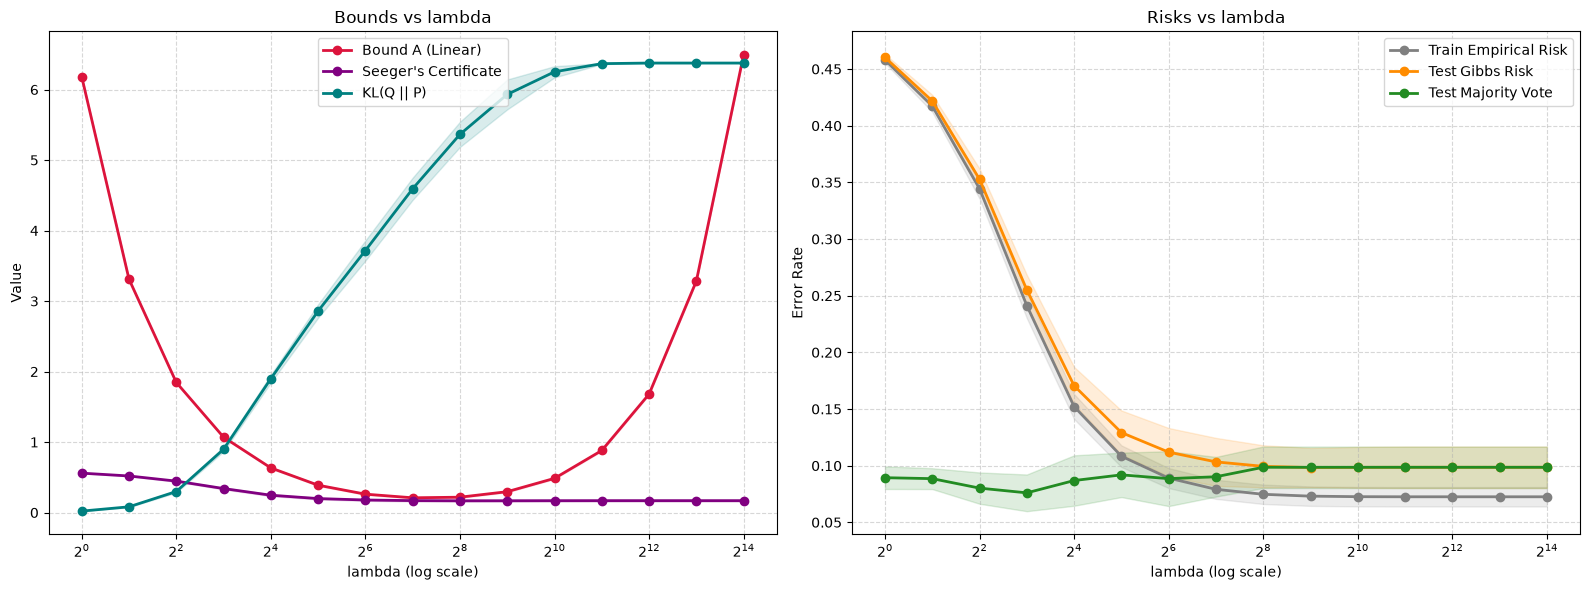

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plots = [
    (
        axes[0],
        ["bound", "seeger", "KL"],
        ["Bound A (Linear)", "Seeger's Certificate", "KL(Q || P)"],
        ["crimson", "purple", "teal"],
        "Value",
        "Bounds vs lambda",
    ),
    (
        axes[1],
        ["emp", "test_gibbs", "test_vote"],
        ["Train Empirical Risk", "Test Gibbs Risk", "Test Majority Vote"],
        ["grey", "darkorange", "forestgreen"],
        "Error Rate",
        "Risks vs lambda",
    )
]

for ax, col_names, labels, colors, y_label, title in plots:
    for col, label, color in zip(col_names, labels, colors):
        grouped = df_wdbc_lambda.groupby("lam")[col]
        mean_val = grouped.mean()
        std_val = grouped.std().fillna(0)
        x = mean_val.index.to_numpy(dtype=float)

        ax.plot(x, mean_val, marker="o", label=label, color=color, linewidth=2)
        ax.fill_between(
            x, mean_val - std_val, mean_val + std_val, color=color, alpha=0.15
        )

    ax.set_xscale("log", base=2)
    ax.set_xlabel("lambda (log scale)")
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

- Bound A is convex vs lambda while Seeger's is significantly tighter and invariant to lambda.
- KL grows as lambda grows as expected.
- Visualizes the bias-variance trade-off as lambda increases, we focus more on minimizing empirical risk, it continues to fall. But at some point, concentrating posterior on training risk no longer improves generalization as test risks plateau.
- It also highlights that voting consistently beats gibbs except for when lambda is high enough as the posterior is concentrated on fewer hypotheses, so there is less diversity for the majority vote to exploit.

The actual choice of lambda should be based on the minimum of Bound A which already takes into account the trade-off.

## 3. Impact of the prior

We examine the prior learnt from a small subset of data instead of the less informative uniform prior by learning the real datasets with the uniform and learnt prior and compare.

In [5]:
cat_rows = []
gauss_rows = []

for name in REAL_DATASETS:
    for seed in SEEDS:
        X, y = get_dataset(name, seed)

        cat_unif = run_categorical(X, y, seed)
        cat_learn = run_categorical(X, y, seed, prior="learned")

        for prior, out in [("uniform", cat_unif), ("learned", cat_learn)]:
            for algo_name in ["A (linear)", "B (McAllester)"]:
                r = out[algo_name]
                cat_rows.append({
                    "dataset": name,
                    "seed": seed,
                    "prior": prior,
                    "algorithm": algo_name,
                    **r
                })

        gauss_zero = run_gaussian(X, y, seed)
        gauss_learn = run_gaussian(X, y, seed, prior="learned")

        for prior, out in [("zero", gauss_zero), ("learned", gauss_learn)]:
            for algo_name in ["A (linear)", "B (McAllester)"]:
                r = out[algo_name]
                gauss_rows.append({
                    "dataset": name,
                    "seed": seed,
                    "prior": prior,
                    "algorithm": algo_name,
                    **r
                })

df_cat = pd.DataFrame(cat_rows)
df_gauss = pd.DataFrame(gauss_rows)

summary_cat = (
    df_cat.drop(["Q", "As", "seed", "dataset"], axis=1).groupby(["prior", "algorithm"]).agg(["mean", "std"]).round(4)
)
summary_gauss = (
    df_gauss.drop(["As", "seed", "dataset"], axis=1).groupby(["prior", "algorithm"]).agg(["mean", "std"]).round(4)
)

print("Categorical (Stumps): Uniform vs Learned (Mean ± Std over some seeds)")
display(summary_cat)

print("Gaussian (Linear): Zero vs Learned (Mean ± Std over some seeds)")
display(summary_gauss)

Categorical (Stumps): Uniform vs Learned (Mean ± Std over some seeds)


bound          seeger              KL          \
                          mean     std    mean     std    mean     std   
prior   algorithm                                                        
learned A (linear)      0.2889  0.1051  0.2769  0.1084  2.2400  1.5958   
        B (McAllester)  0.2941  0.1053  0.2789  0.1116  2.5584  1.5448   
uniform A (linear)      0.3013  0.1036  0.2876  0.1088  5.0467  0.9417   
        B (McAllester)  0.3041  0.1028  0.2875  0.1095  5.2609  1.1404   

                           emp            neff         test_gibbs          \
                          mean     std    mean     std       mean     std   
prior   algorithm                                                           
learned A (linear)      0.1838  0.0714  3.4522  3.5434     0.2038  0.0810   
        B (McAllester)  0.1842  0.0726  2.3422  2.0421     0.2026  0.0818   
uniform A (linear)      0.1829  0.0702  2.9866  1.7604     0.2055  0.0817   
        B (McAllester)  0.1821  0.0713  2.7581  2.0342     0.2045  0.0820   

                       test_vote          
                            mean     std  
prior   algorithm                         
learned A (linear)        0.1998  0.0865  
        B (McAllester)    0.1998  0.0844  
uniform A (linear)        0.1969  0.0851  
        B (McAllester)    0.1979  0.0838

Gaussian (Linear): Zero vs Learned (Mean ± Std over some seeds)


bound          seeger               KL           \
                          mean     std    mean     std     mean      std   
prior   algorithm                                                          
learned A (linear)      0.2747  0.1220  0.2599  0.1283   4.5240   1.6703   
        B (McAllester)  0.2776  0.1200  0.2593  0.1285   4.6684   1.8562   
zero    A (linear)      0.3317  0.1161  0.3120  0.1302  22.6167  18.9943   
        B (McAllester)  0.3319  0.1170  0.3112  0.1297  24.5595  22.3327   

                           emp         test_gibbs         test_vote          
                          mean     std       mean     std      mean     std  
prior   algorithm                                                            
learned A (linear)      0.1635  0.0785     0.1795  0.0883    0.1417  0.0870  
        B (McAllester)  0.1639  0.0806     0.1793  0.0903    0.1411  0.0869  
zero    A (linear)      0.1783  0.0829     0.1956  0.0928    0.1420  0.0845  
        B (McAllester)  0.1761  0.0822     0.1932  0.0925    0.1414  0.0839

The bounds do become tighter (significantly for gaussian, insignificantly for stumps) and empirical risks are slightly lower.

Impact of the prior on KL, Seeger and test risks.

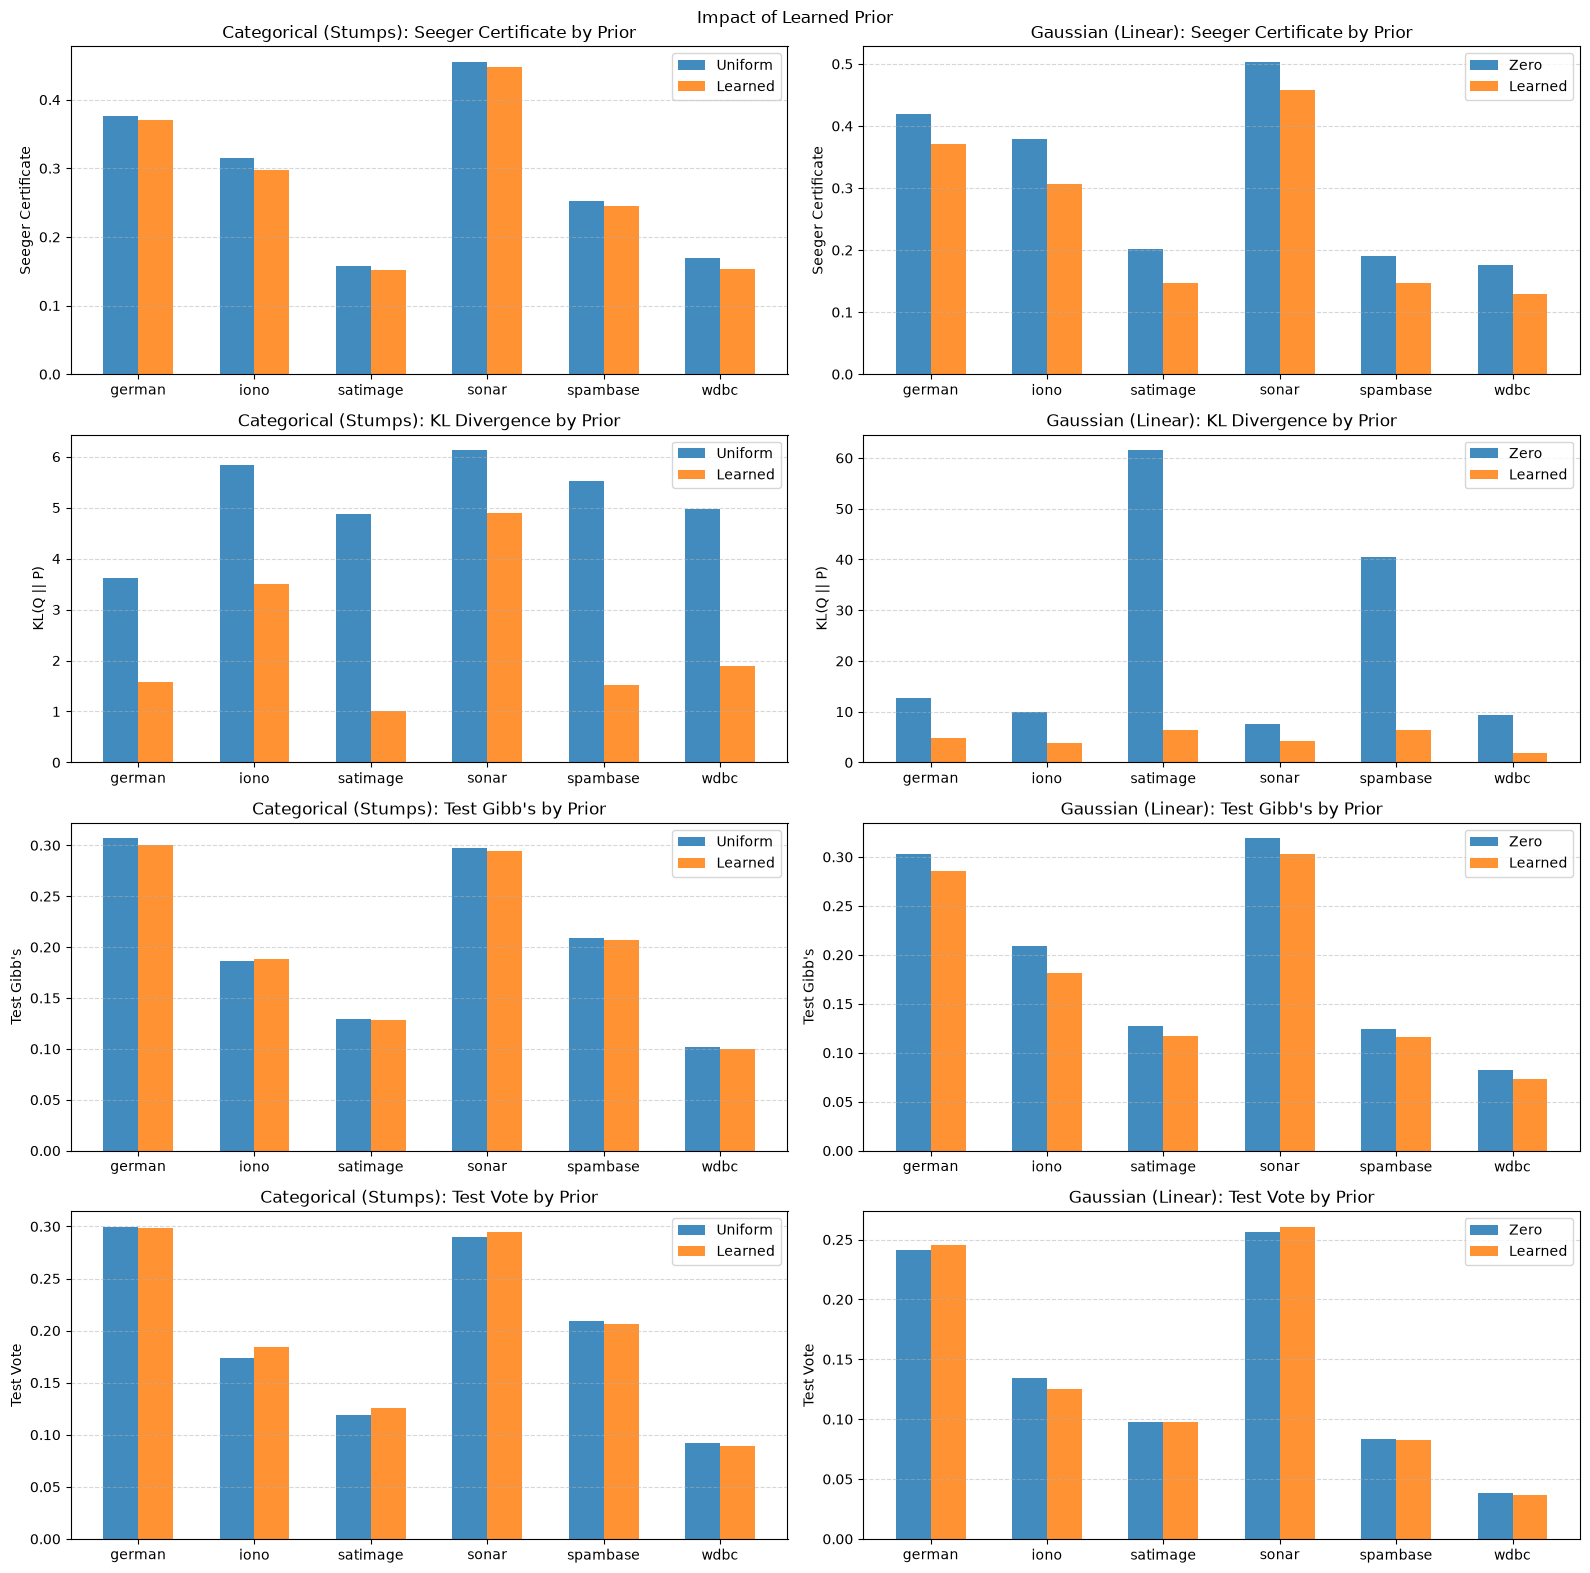

In [6]:
fig, axes = plt.subplots(4, 2, figsize=(16, 16))

# Comparison across datasets
cat_summary_per_dataset = (
    df_cat.groupby(["dataset", "prior"])[["KL", "seeger", "test_gibbs", "test_vote"]].mean().unstack()
)
gauss_summary_per_dataset = (
    df_gauss.groupby(["dataset", "prior"])[["KL", "seeger", "test_gibbs", "test_vote"]].mean().unstack()
)

datasets = cat_summary_per_dataset.index
x = np.arange(len(datasets))
width = 0.3

def plot_bar(ax, data, prior1, prior2, ylabel, title):
    ax.bar(
        x - width / 2, data[prior1], width,
        label=prior1.capitalize(), alpha=0.85,
    )
    ax.bar(
        x + width / 2, data[prior2], width,
        label=prior2.capitalize(), alpha=0.85,
    )
    ax.set_xticks(x)
    ax.set_xticklabels(datasets)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.5)


plot_bar(
    axes[0, 0], cat_summary_per_dataset["seeger"],
    "uniform", "learned", "Seeger Certificate", "Categorical (Stumps): Seeger Certificate by Prior"
)
plot_bar(
    axes[0, 1], gauss_summary_per_dataset["seeger"],
    "zero", "learned", "Seeger Certificate", "Gaussian (Linear): Seeger Certificate by Prior"
)
plot_bar(
    axes[1, 0], cat_summary_per_dataset["KL"],
    "uniform", "learned", "KL(Q || P)", "Categorical (Stumps): KL Divergence by Prior"
)
plot_bar(
    axes[1, 1], gauss_summary_per_dataset["KL"],
    "zero", "learned", "KL(Q || P)", "Gaussian (Linear): KL Divergence by Prior"
)
plot_bar(
    axes[2, 0], cat_summary_per_dataset["test_gibbs"],
    "uniform", "learned", "Test Gibb's", "Categorical (Stumps): Test Gibb's by Prior"
)
plot_bar(
    axes[2, 1], gauss_summary_per_dataset["test_gibbs"],
    "zero", "learned", "Test Gibb's", "Gaussian (Linear): Test Gibb's by Prior"
)
plot_bar(
    axes[3, 0], cat_summary_per_dataset["test_vote"],
    "uniform", "learned", "Test Vote", "Categorical (Stumps): Test Vote by Prior"
)
plot_bar(
    axes[3, 1], gauss_summary_per_dataset["test_vote"],
    "zero", "learned", "Test Vote", "Gaussian (Linear): Test Vote by Prior"
)

plt.suptitle("Impact of Learned Prior")
plt.tight_layout()
plt.show()

In general, the linear classifiers see more drastic changes. This is due to the prior being zero which is very uninformative, as a good classifier usually need larger weights, even compared to the uniform prior of stumps.

In both cases, KL decreases significantly, this means that a small set is enough to learn a prior that assigns higher weights to more informative stumps.

Since KL decreases with the empirical risk somewhat the same or slight improvement, bounds and certificates are tighter.

Test risks remain essentially unchanged or decrease in some gaussian cases as the learned prior guides the optimization. This is because prior is used to certify an accuracy and somewhat regularizes the model, thus no change in risk probably means that the bound sample $S$ is large enough to learn the optimal posterior.

This can somewhat be seen with the gaussian gibbs test error improving, because there isn't enough sample to reach the optimum (learning continuous weights requires more information than picking from finite pool of stumps) without guidance from a good prior, while the vote test error unchanging, because a sub-optimal posterior can be canceled out by voting while gibbs samples its models which depend more on a good posterior.

The learned prior is legitimate here (probably $1 - \delta$) because our prior is chosen independently of $S$.

## 4. Changing the family of distributions

The dirac on the best stump and the uniform on $k$ best stumps have been added to `pacbayes_tools.py`.

In [7]:
rows = []

for name in REAL_DATASETS:
    for seed in SEEDS:
        X, y = get_dataset(name, seed)

        cat = run_categorical(X, y, seed, dirac=True, k_top=10)

        for algo_name, r in cat.items():
            rows.append({
                "dataset": name,
                "seed": seed,
                "family": "stumps",
                "algorithm": algo_name,
                "name": f"stumps ({algo_name})",
                **r
            })

        gauss = run_gaussian(X, y, seed)

        for algo_name, r in gauss.items():
            rows.append({
                "dataset": name,
                "seed": seed,
                "family": "linear",
                "algorithm": algo_name,
                "name": f"linear ({algo_name})",
                **r
            })

df = pd.DataFrame(rows)

summary = (
    df
        .drop(["Q", "As", "seed", "dataset", "name"], axis=1)
        .groupby(["family", "algorithm"]).agg(["mean", "std"]).round(4)
)

print("Comparison of Distributions (Mean ± Std over some seeds)")
display(summary)

Comparison of Distributions (Mean ± Std over some seeds)


bound          seeger               KL           \
                         mean     std    mean     std     mean      std   
family algorithm                                                          
linear A (linear)      0.3317  0.1161  0.3120  0.1302  22.6167  18.9943   
       B (McAllester)  0.3319  0.1170  0.3112  0.1297  24.5595  22.3327   
stumps A (linear)      0.3013  0.1036  0.2876  0.1088   5.0467   0.9417   
       B (McAllester)  0.3041  0.1028  0.2875  0.1095   5.2609   1.1404   
       Dirac           0.3067  0.1040  0.2895  0.1111   6.2500   0.6144   
       Top-10          0.3179  0.1077  0.3049  0.1143   3.9474   0.6144   

                          emp            neff         test_gibbs          \
                         mean     std    mean     std       mean     std   
family algorithm                                                           
linear A (linear)      0.1783  0.0829     NaN     NaN     0.1956  0.0928   
       B (McAllester)  0.1761  0.0822     NaN     NaN     0.1932  0.0925   
stumps A (linear)      0.1829  0.0702  2.9866  1.7604     0.2055  0.0817   
       B (McAllester)  0.1821  0.0713  2.7581  2.0342     0.2045  0.0820   
       Dirac           0.1800  0.0708     NaN     NaN     0.2040  0.0844   
       Top-10          0.2031  0.0734     NaN     NaN     0.2198  0.0818   

                      test_vote          
                           mean     std  
family algorithm                         
linear A (linear)        0.1420  0.0845  
       B (McAllester)    0.1414  0.0839  
stumps A (linear)        0.1969  0.0851  
       B (McAllester)    0.1979  0.0838  
       Dirac             0.2040  0.0844  
       Top-10            0.1982  0.0839

KL of gaussian being high is discussed in question 3, the bound and seeger being higher is probably also because it requires more information to learn.

However, its empirical risk and test gibbs risk are similar but with a significant decrease in the test vote risk while the decision stumps are barely better than the single best stump from Dirac!

Note: neff of Dirac is 1 and top-10 is 10.

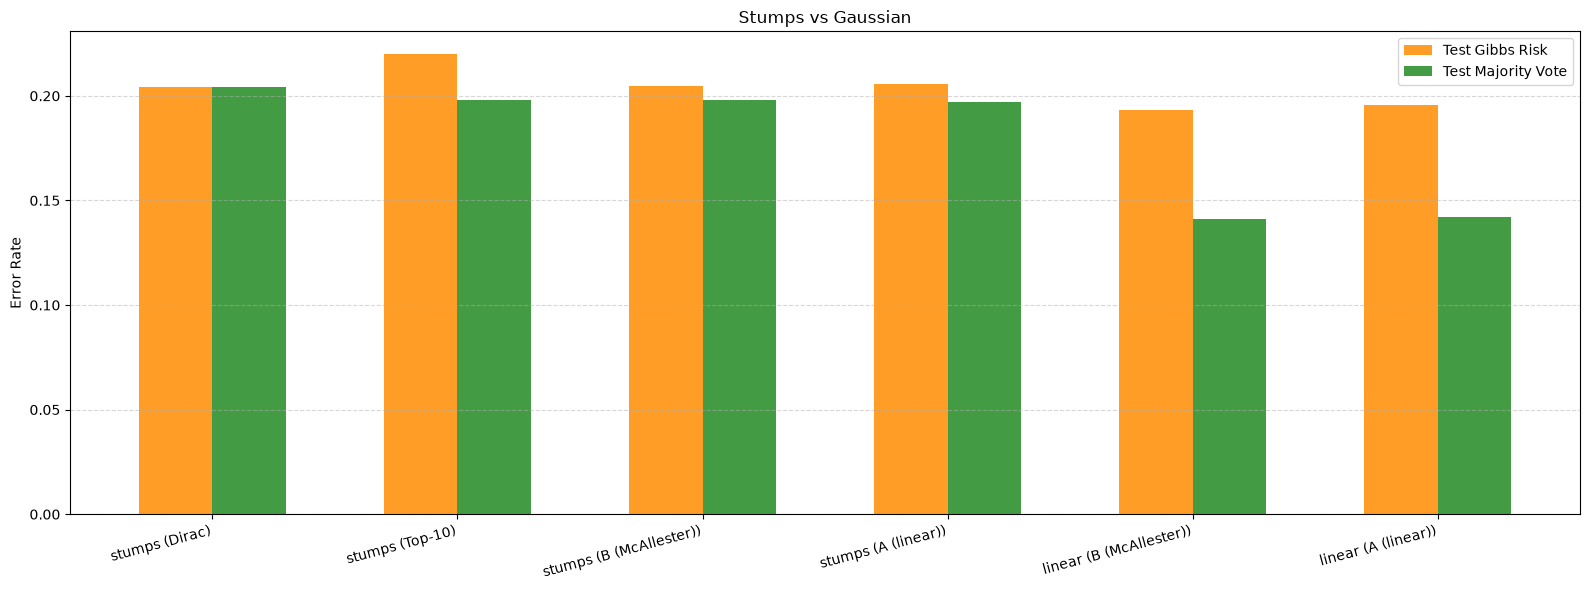

In [8]:
model_means = df.groupby("name")[["test_gibbs", "test_vote"]].mean()

order = [
    "stumps (Dirac)",
    "stumps (Top-10)",
    "stumps (B (McAllester))",
    "stumps (A (linear))",
    "linear (B (McAllester))",
    "linear (A (linear))",
]
model_means = model_means.loc[order]

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(order))

ax.bar(
    x - width / 2, model_means["test_gibbs"], width,
    label="Test Gibbs Risk", color="darkorange", alpha=0.85,
)
ax.bar(
    x + width / 2, model_means["test_vote"], width,
    label="Test Majority Vote", color="forestgreen", alpha=0.85,
)

ax.set_ylabel("Error Rate")
ax.set_title("Stumps vs Gaussian")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=15, ha="right")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

This is because, as we are minimizing the bound Gibbs risk, we are trying to find good individual classifiers without necessarily considering combinations which give a strong majority vote. So we are just trying to get the best stumps, => no diversity, rather than considering, for example 2 bad stumps but can complement eachothers like in Gradient Boosting. Thus it behaves similarly to the single best stump (in our case, it only uses 3 stumps).

Linear classifiers on the other hand, their combination (vote) is still a linear classifier but as the gaussian gibbs risk rewards large margins, this is somewhat similar to finding a linear classifier with the largest margins, it's like it's some sort of support vector machine! Since the majority vote is determined by the mean linear classifier, improving the gibbs classifier also tends to improve it. And of course a linear classifier is a way stronger learner than a stump as it can take into account many features at once, thus it is stronger than the probably singular stump.

## 5. Classical learning versus bound minimization

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import warnings

warnings.filterwarnings("ignore")

from ensembles_lib import make_models


REAL_DATASETS += ["libras", "yeast3", "segmentation", "vehicle", "glass", "wine", "pima", "heart", "australian"]
REAL_DATASETS = list(set(REAL_DATASETS))


rows = []

for name in REAL_DATASETS:
    print(f"Processing dataset: {name}")
    for seed in SEEDS:
        X, y = real_dataset(name)

        Xtr, Xte, ytr, yte = train_test_split(
            X, y, test_size=0.3, stratify=y, random_state=seed
        )

        made_models = make_models()
        classical_models = {
            "AdaBoost-d1": made_models["AdaBoost-d1"],
            "AdaBoost-d3": made_models["AdaBoost-d3"],
            "HistGBM": made_models["HistGBM"],
            "Random Forest": made_models["RF"],
            "Logistic Regression": make_pipeline(
                StandardScaler(), LogisticRegression(max_iter=1000)
            ),
        }

        for m_name, model in classical_models.items():
            model.fit(Xtr, ytr)
            err = float(np.mean(model.predict(Xte) != yte))
            rows.append({
                "dataset": name,
                "seed": seed,
                "model": m_name,
                "test_risk": err,
                "certificate": np.nan,
            })

        c_out = run_categorical(X, y, seed=seed, prior="learned")
        g_out = run_gaussian(X, y, seed=seed, prior="learned")

        for algo in ["A (linear)", "B (McAllester)"]:
            rows.append({
                "dataset": name,
                "seed": seed,
                "model": f"pac-bayes stumps ({algo})",
                "test_risk": c_out[algo]["test_vote"],
                "certificate": c_out[algo]["seeger"],
            })
            rows.append({
                "dataset": name,
                "seed": seed,
                "model": f"pac-bayes linear ({algo})",
                "test_risk": g_out[algo]["test_vote"],
                "certificate": g_out[algo]["seeger"],
            })

df = pd.DataFrame(rows)

summary = (
    df.groupby(["model"])[["test_risk", "certificate"]].agg(["mean", "std"]).round(4)
)

print("Classical vs PAC-Bayesian Bound Minimization (Mean ± Std over some seeds)")
display(summary)

Processing dataset: wdbc
Processing dataset: pima
Processing dataset: libras
Processing dataset: vehicle
Processing dataset: wine
Processing dataset: sonar
Processing dataset: iono
Processing dataset: heart
Processing dataset: yeast3
Processing dataset: glass
Processing dataset: australian
Processing dataset: german
Processing dataset: segmentation
Processing dataset: spambase
Processing dataset: satimage
Classical vs PAC-Bayesian Bound Minimization (Mean ± Std over some seeds)


test_risk         certificate        
                                       mean     std        mean     std
model                                                                  
AdaBoost-d1                          0.1115  0.0829         NaN     NaN
AdaBoost-d3                          0.1060  0.0870         NaN     NaN
HistGBM                              0.1032  0.0861         NaN     NaN
Logistic Regression                  0.1195  0.0884         NaN     NaN
Random Forest                        0.1008  0.0808         NaN     NaN
pac-bayes linear (A (linear))        0.1285  0.0822      0.2809  0.1188
pac-bayes linear (B (McAllester))    0.1280  0.0827      0.2797  0.1188
pac-bayes stumps (A (linear))        0.1792  0.0885      0.2715  0.1075
pac-bayes stumps (B (McAllester))    0.1811  0.0896      0.2732  0.1106

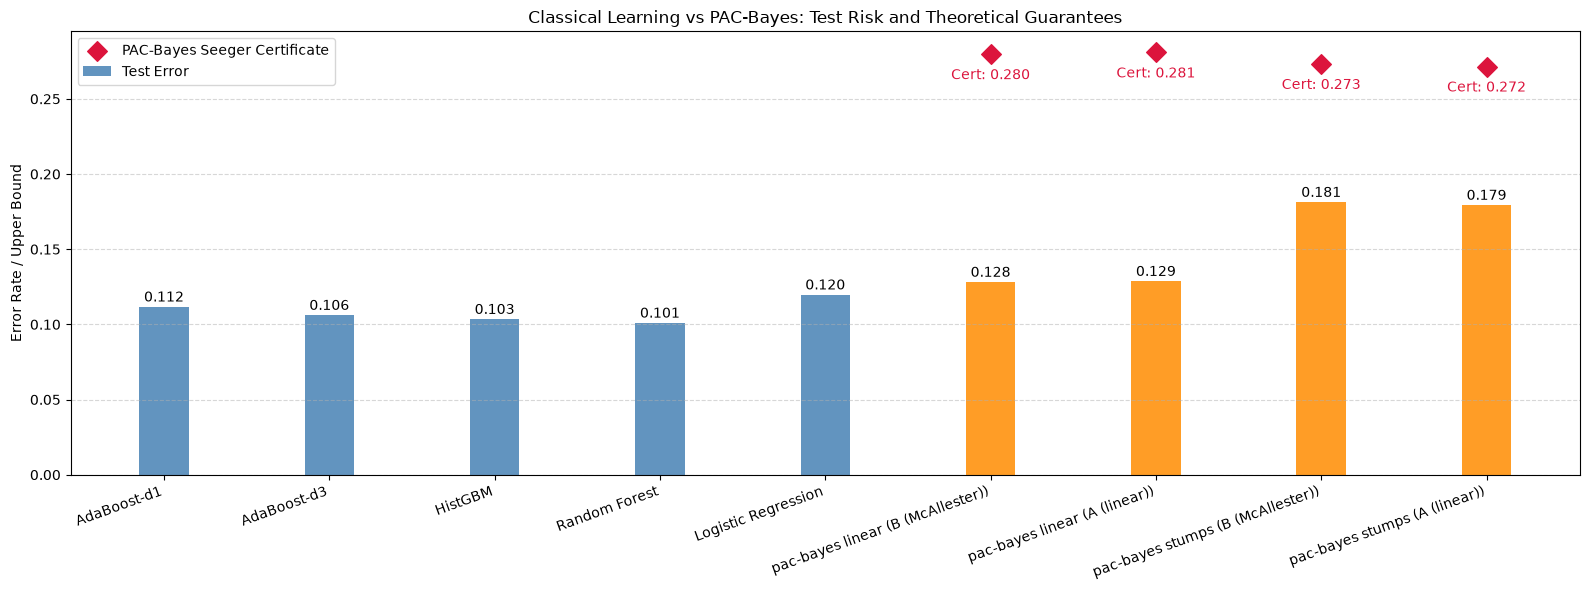

In [10]:
summary_means = df.groupby("model")[["test_risk", "certificate"]].mean()

model_order = [
    "AdaBoost-d1",
    "AdaBoost-d3",
    "HistGBM",
    "Random Forest",
    "Logistic Regression",
    "pac-bayes linear (B (McAllester))",
    "pac-bayes linear (A (linear))",
    "pac-bayes stumps (B (McAllester))",
    "pac-bayes stumps (A (linear))",
]
summary_means = summary_means.loc[model_order]

fig, ax = plt.subplots(figsize=(16, 6))
x = np.arange(len(model_order))

bars = ax.bar(
    x, summary_means["test_risk"], width,
    label="Test Error",
    color=["steelblue" if "pac-bayes" not in m else "darkorange" for m in model_order],
    alpha=0.85,
)

has_cert = ~summary_means["certificate"].isna()
ax.scatter(
    x[has_cert], summary_means["certificate"][has_cert],
    color="crimson", s=100, zorder=5, label="PAC-Bayes Seeger Certificate", marker="D",
)

for i, m in enumerate(model_order):
    err = summary_means.loc[m, "test_risk"]
    cert = summary_means.loc[m, "certificate"]
    ax.annotate(
        f"{err:.3f}",
        xy=(i, err),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
    )
    if not np.isnan(cert):
        ax.annotate(
            f"Cert: {cert:.3f}",
            xy=(i, cert),
            xytext=(0, -18),
            textcoords="offset points",
            ha="center",
            color="crimson",
        )

ax.set_ylabel("Error Rate / Upper Bound")
ax.set_title("Classical Learning vs PAC-Bayes: Test Risk and Theoretical Guarantees")
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=20, ha="right")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In general, the classical learning approach predicts better. PAC-Bayes stumps are most similar to AdaBoost in function but perform relatively poorly. While PAC-Bayes averages individually accurate stumps (due to minimizing gibbs risk) which could share identical mistakes, AdaBoost reweights misclassified points, forcing new stumps to be complementary. The PAC-Bayes linear classifier is competitive with Logistic Regression, but slightly more conservative probably due to the prior regularizer.

PAC-Bayesian approach offers:
1. A statistical certificate (e.g. Seeger's bound) that guarantees with high probability ($1 - \delta$) on the true generalization error $R_{\mathcal D}(h)$ without a held out empirical test set.
2. Regularization built-in without needing cross-validation directly from some priors $P$. This also means that if we know in advance (maybe from prior studies or from transfer learning), we can use that as the prior of our new problem to guide the learning.
3. Because the algorithm directly minimizes the upper bound on the generalization risk, it is safeguarded against overfitting.

At the price:
1. As the certificate is always valid, the optimization is constrained by the complexity penalty $\mathrm{KL}(Q || P)$ and cannot freely explore the hypothesis space. This causes a performance gap compared to classical ensembles.
2. To achieve tight certificates, PAC-Bayes must reserve a portion of the training set to learn the prior $P$. Consequently, the posterior $Q$ is trained on fewer examples.
3. PAC-Bayesian bounds bound the Gibbs risk $\mathbb{E}_{h \sim Q} R(h)$, which is linear in $Q$ for discrete hypotheses. As established, minimizing Gibbs risk provides no diversity or complementarity, making PAC-Bayes ensembles of weak learners inferior to boosted ensembles.

PAC-Bayes brings to Ensemble Methods:
1. PAC-Bayesian theory explains *why* ensembles work: the majority vote error is bounded by twice the Gibbs risk ($R(B_Q) \le 2 R(G_Q)$), and in practice, voting cancels independent errors, beating individual voters.
2. In mission-critical applications (medicine, autonomous systems, finance) where empirical test performance alone is insufficient, PAC-Bayes provides provable performance certificates.
3. If the sole objective is predictive performance, classical ensembles remain superior due to reweighting and unconstrained complexity. If the objective is certified PAC risk guarantees, PAC-Bayesian bound minimization is a good choice.